df_bt usable range after dropna(subset): 2021-01-21 00:00:00 -> 2022-01-31 00:00:00
train_bt rows: 1 | test_bt rows: 10
[BACKTEST] Linear MAE:        15.63
[BACKTEST] Random Forest MAE: 15.63


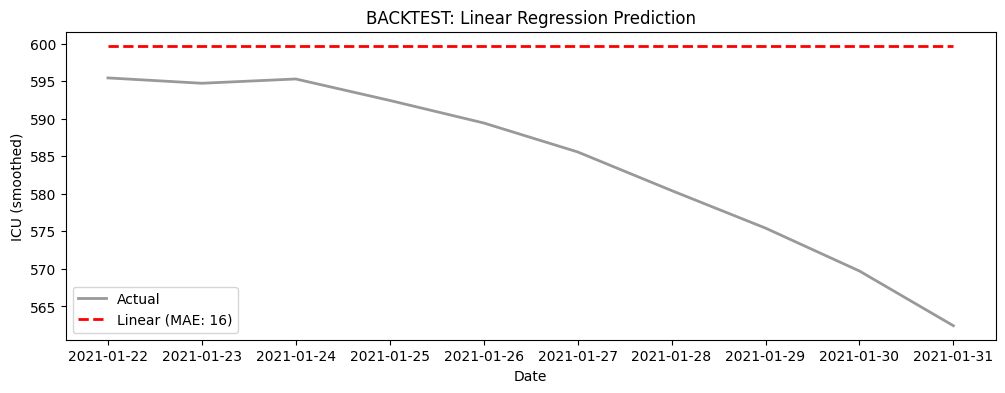

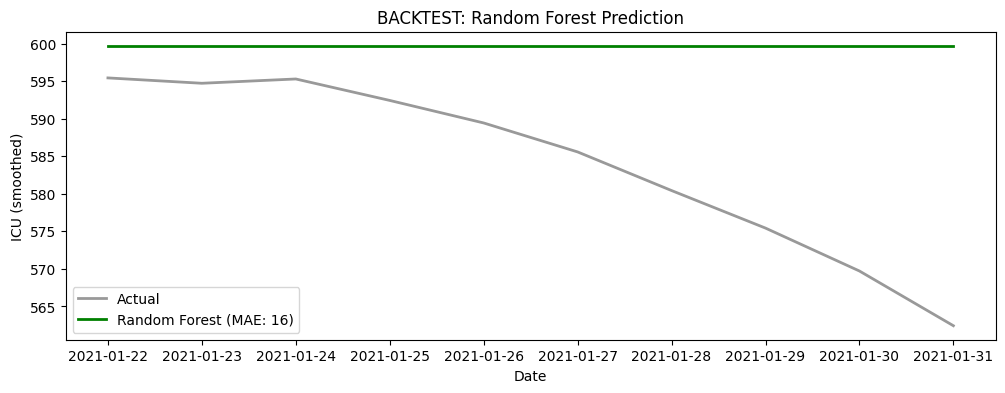

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# ============================================================
# BACKTEST BLOCK (same logic, consistently renamed variables)
# You will change the dates yourself.
# ============================================================

# 1. LOAD & ENGINEER DATA (Backtest copy)
url_bt = "/Users/chandana/Documents/Python for Data Science/compact.csv"
df_bt = pd.read_csv(url_bt)

df_bt["date"] = pd.to_datetime(df_bt["date"])
df_bt = df_bt[df_bt["country"] == "Netherlands"].set_index("date").sort_index()

# Change these dates yourself
df_bt = df_bt.loc["2020-01-01":"2022-01-31",
                  ["new_cases", "new_deaths", "hosp_patients",
                   "people_fully_vaccinated_per_hundred", "country", "icu_patients"]]

# Better than fillna(0) for these columns
df_bt["hosp_patients"] = df_bt["hosp_patients"].ffill()
df_bt["people_fully_vaccinated_per_hundred"] = df_bt["people_fully_vaccinated_per_hundred"].ffill()

# Feature Engineering (same as yours)
df_bt["hosp_lag_7_bt"]  = df_bt["hosp_patients"].rolling(7).mean().shift(7)
df_bt["hosp_lag_14_bt"] = df_bt["hosp_lag_7_bt"].shift(7)
df_bt["cases_lag_7_bt"] = df_bt["new_cases"].rolling(7).mean().shift(7)
df_bt["cases_lag_14_bt"] = df_bt["cases_lag_7_bt"].shift(14)

# (smoothed view as target, same as yours)
df_bt["icu_patients_smooted_bt"] = df_bt["icu_patients"].rolling(7).mean()


# 2. SPLIT DATA (Time-Based) (Backtest copy)
# Change this cutoff + test window yourself
cutoff_bt = "2021-01-22"

features_bt = [
    "cases_lag_14_bt",
    "cases_lag_7_bt",
    "hosp_lag_7_bt",
    "hosp_lag_14_bt",
    "people_fully_vaccinated_per_hundred",
]

target_bt = "icu_patients_smooted_bt"

# Instead of dropping everything, drop only rows needed for features + target
df_bt = df_bt.dropna(subset=features_bt + [target_bt])

# Quick debug so you can see what's happening
print("df_bt usable range after dropna(subset):", df_bt.index.min(), "->", df_bt.index.max())

train_bt = df_bt[df_bt.index < cutoff_bt]
test_bt  = df_bt.loc[cutoff_bt:"2021-01-31"]  # your end date

print("train_bt rows:", len(train_bt), "| test_bt rows:", len(test_bt))

if len(train_bt) == 0:
    raise ValueError(
        f"Empty training set (train_bt has 0 rows). "
        f"Move cutoff_bt later than {df_bt.index.min().date()} or start earlier."
    )

X_train_bt, y_train_bt = train_bt[features_bt], train_bt[target_bt]
X_test_bt,  y_test_bt  = test_bt[features_bt],  test_bt[target_bt]


# 3. MODELS (Backtest copy)
WINDOW_BT = 7
EPS_BT = 1e-6

# Step A: Baseline (Linear Regression)
lr_bt = LinearRegression()
lr_bt.fit(X_train_bt, y_train_bt)
pred_lr_bt = lr_bt.predict(X_test_bt)
mae_lr_bt = mean_absolute_error(y_test_bt, pred_lr_bt)

# Step B: Random Forest
rf_bt = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    min_samples_leaf=5,
    min_samples_split=5,
    random_state=42,
)
rf_bt.fit(X_train_bt, y_train_bt)
pred_rf_bt = rf_bt.predict(X_test_bt)

scaled_pred_rf_bt = np.zeros_like(pred_rf_bt)

# Scaling the predicted value with the target value 7 days behind
for t_bt in range(len(pred_rf_bt)):
    if t_bt < WINDOW_BT + 3:
        scaled_pred_rf_bt[t_bt] = pred_rf_bt[t_bt]
    else:
        y_obs_window_bt  = y_test_bt.iloc[t_bt - WINDOW_BT - 3 : t_bt - WINDOW_BT]
        y_pred_window_bt = pred_rf_bt[t_bt - WINDOW_BT - 3 : t_bt - WINDOW_BT]

        alpha_t_bt = np.mean(y_obs_window_bt) / (np.mean(y_pred_window_bt) + EPS_BT)
        scaled_pred_rf_bt[t_bt] = alpha_t_bt * pred_rf_bt[t_bt]

mae_rf_bt = mean_absolute_error(y_test_bt, scaled_pred_rf_bt)

print(f"[BACKTEST] Linear MAE:        {mae_lr_bt:.2f}")
print(f"[BACKTEST] Random Forest MAE: {mae_rf_bt:.2f}")

# =========================
# 4. VISUALIZATION (separate graphs)
# =========================


# Graph Linear prediction only (with actual as faint reference)
plt.figure(figsize=(12, 4))
plt.plot(test_bt.index, y_test_bt, color="black", linewidth=2, alpha=0.4, label="Actual")
plt.plot(test_bt.index, pred_lr_bt, color="red", linestyle="--", linewidth=2, label=f"Linear (MAE: {mae_lr_bt:.0f})")
plt.title("BACKTEST: Linear Regression Prediction")
plt.xlabel("Date")
plt.ylabel("ICU (smoothed)")
plt.legend()
plt.show()

# Graph Random Forest prediction only (with actual as faint reference)
plt.figure(figsize=(12, 4))
plt.plot(test_bt.index, y_test_bt, color="black", linewidth=2, alpha=0.4, label="Actual")
plt.plot(test_bt.index, scaled_pred_rf_bt, color="green", linewidth=2, label=f"Random Forest (MAE: {mae_rf_bt:.0f})")
plt.title("BACKTEST: Random Forest Prediction")
plt.xlabel("Date")
plt.ylabel("ICU (smoothed)")
plt.legend()
plt.show()



## FORECAST

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# 1. LOAD & ENGINEER DATA (Recap)
url = "/Users/chandana/Documents/Python for Data Science/compact.csv"
df = pd.read_csv(url)
df['date'] = pd.to_datetime(df['date'])
df = df[df['country'] == 'Netherlands'].set_index('date').sort_index()

# include Jan 31, 2022 since your test goes until then
df = df.loc['2020-10-01':'2022-01-31',
            ['new_cases', 'new_deaths', 'hosp_patients', 'people_fully_vaccinated_per_hundred', 'country', 'icu_patients']]

# Better than fillna(0) for these columns
df['hosp_patients'] = df['hosp_patients'].ffill()
df['people_fully_vaccinated_per_hundred'] = df['people_fully_vaccinated_per_hundred'].ffill()

# Feature Engineerin
df['hosp_lag_7'] = df['hosp_patients'].rolling(7).mean().shift(7)             
df['hosp_lag_14'] = df['hosp_lag_7'].shift(7)            
df['cases_lag_7'] = df['new_cases'].rolling(7).mean().shift(7)     
df['cases_lag_14'] = df['cases_lag_7'].shift(14) 

#  (if you still want a smoothed view, but NO leakage):
df['icu_patients_smooted'] = df['icu_patients'].rolling(7).mean()    




df = df.dropna()

# 2. SPLIT DATA (Time-Based)
# --------------------------
cutoff = '2021-12-01'
features = ['cases_lag_14', 'cases_lag_7', 'hosp_lag_7', 'hosp_lag_14','people_fully_vaccinated_per_hundred']
# features = ['cases_lag_14', 'cases_smooth_7', 'hosp_lag_7', 'hosp_lag_14']

target = "icu_patients_smooted"  # assignment target replaced with smoothened

train = df[df.index < "2021-12-01"]
test  = df["2021-12-01":"2022-01-31"]

X_train, y_train = train[features], train[target]
X_test, y_test   = test[features], test[target]


Linear MAE:        91.14
Random Forest MAE: 39.30


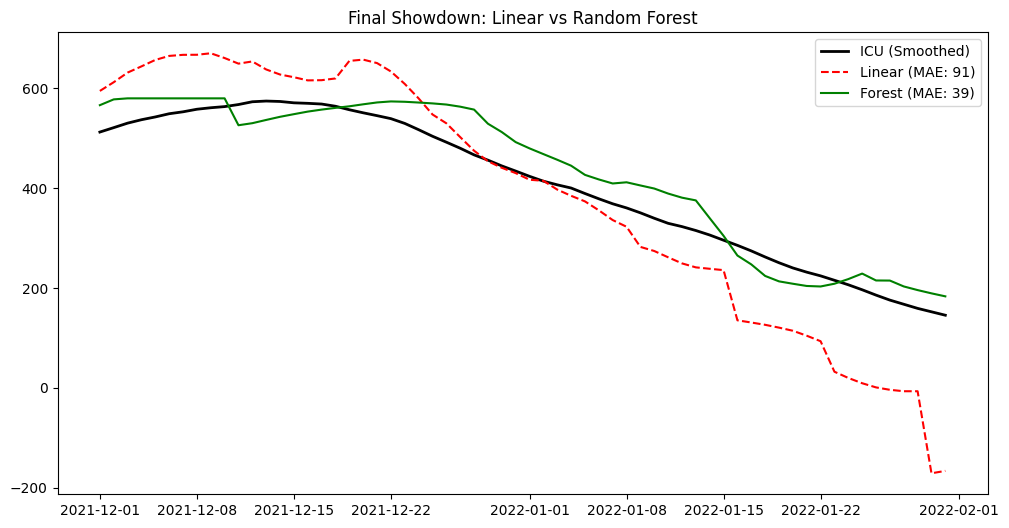

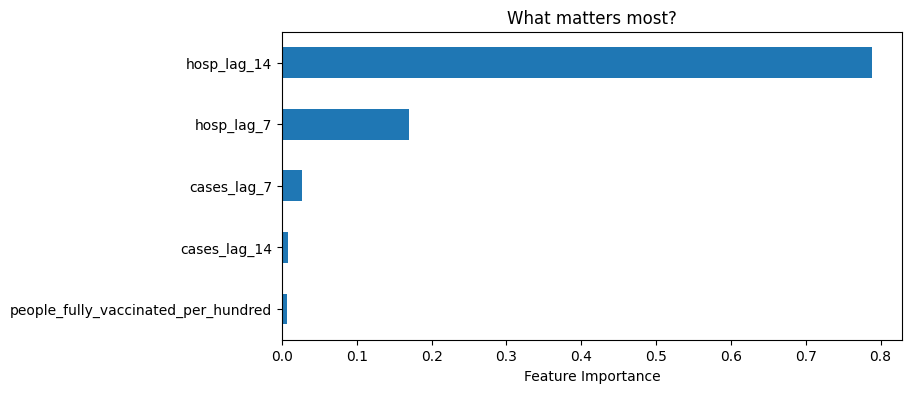

In [3]:
import numpy as np

WINDOW = 7      # Dictates the lag of the scaler
EPS = 1e-6      # A stabilizer value

# Step A: Baseline (Linear Regression)
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)
mae_lr = mean_absolute_error(y_test, pred_lr)


#Random Forest
rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    min_samples_leaf=5,
    min_samples_split=5,
    random_state=42,
)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

scaled_pred_rf = np.zeros_like(pred_rf)

# Scaling the predicted value with the target value 7 days behind
for t in range(len(pred_rf)):

    # Not touching the prediction because of the window
    if t < WINDOW+3:
        scaled_pred_rf[t] = pred_rf[t]
    else:

        # Calculating the mean error for Window-3 : Window
        y_obs_window = y_test[t-WINDOW-3:t-WINDOW]
        y_pred_window = pred_rf[t-WINDOW-3:t-WINDOW]

        alpha_t = (
            np.mean(y_obs_window)
            / (np.mean(y_pred_window) + EPS)
        )

        # Scaling each day for the error
        scaled_pred_rf[t] = alpha_t * pred_rf[t]

mae_rf = mean_absolute_error(y_test, scaled_pred_rf)
print(f"Linear MAE:        {mae_lr:.2f}")
print(f"Random Forest MAE: {mae_rf:.2f}")

# Visualization
plt.figure(figsize=(12, 6))
plt.plot(test.index, y_test, color="black", label="ICU (Smoothed)", linewidth=2)
plt.plot(test.index, pred_lr, color="red", linestyle="--", label=f"Linear (MAE: {mae_lr:.0f})")
plt.plot(test.index, scaled_pred_rf, color="green", label=f"Forest (MAE: {mae_rf:.0f})")
plt.title("Final Showdown: Linear vs Random Forest")
plt.legend()
plt.show()

# Opening the black box
importances = pd.Series(rf.feature_importances_, index=features).sort_values()

plt.figure(figsize=(8, 4))
importances.plot(kind="barh")  
plt.title("What matters most?")
plt.xlabel("Feature Importance")
plt.show()

XGBoost MAE:       34.58


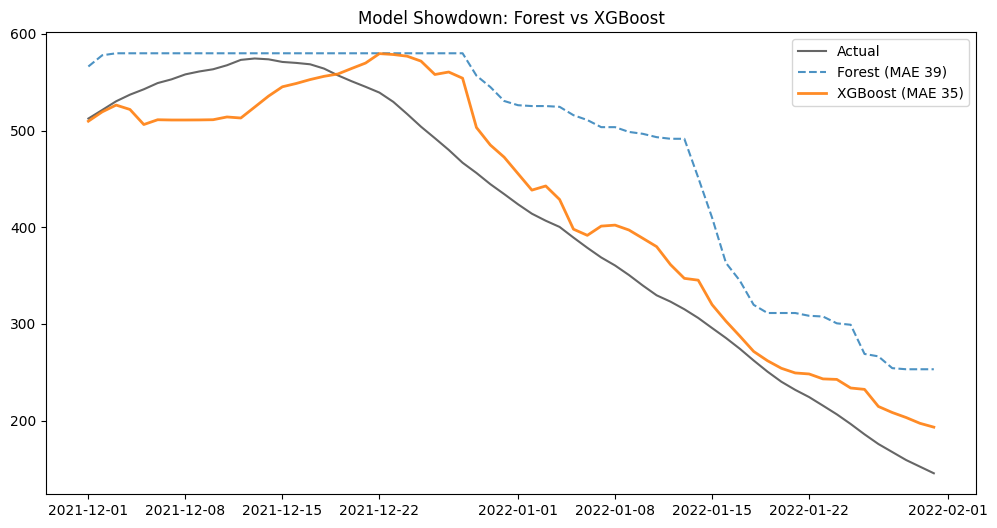

In [4]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=42,
    n_jobs=-1
)

xgb.fit(X_train, y_train)
pred_xgb = xgb.predict(X_test)

scaled_pred_xgb = np.zeros_like(pred_xgb)

for t in range(len(pred_xgb)):
    if t < WINDOW+3:
        scaled_pred_xgb[t] = pred_xgb[t]
    else:
        y_obs_window = y_test[t-WINDOW-3:t-WINDOW]
        y_pred_window = pred_xgb[t-WINDOW-3:t-WINDOW]

        alpha_t = (
            np.mean(y_obs_window)
            / (np.mean(y_pred_window) + EPS)
        )

        scaled_pred_xgb[t] = alpha_t * pred_xgb[t]

mae_xgb = mean_absolute_error(y_test, scaled_pred_xgb)

print(f"XGBoost MAE:       {mae_xgb:.2f}")

plt.figure(figsize=(12, 6))
plt.plot(test.index, y_test, color="black", alpha=0.6, label="Actual")
plt.plot(test.index, pred_rf, linestyle="--", alpha=0.8, label=f"Forest (MAE {mae_rf:.0f})")
plt.plot(test.index, scaled_pred_xgb, linewidth=2, alpha=0.9, label=f"XGBoost (MAE {mae_xgb:.0f})")
plt.title("Model Showdown: Forest vs XGBoost")
plt.legend()
plt.show()


In [5]:
# --------------------------------------------------
# JANUARY 2022 EXPORT (XGBOOST – ICU – NETHERLANDS)
# --------------------------------------------------
pred_best_icu = scaled_pred_xgb  # final ICU model predictions

jan_mask = (X_test.index >= "2022-01-01") & (X_test.index <= "2022-01-31")

jan_dates = X_test.index[jan_mask]
jan_predictions_icu = pred_best_icu[jan_mask]

final_predictions_icu = pd.DataFrame({
    "Date": jan_dates,
    "Region": "Netherlands",
    "Predicted ICU patients": jan_predictions_icu,
    "Actual ICU patients": y_test.loc[jan_dates].values
})

final_predictions_icu["Predicted ICU patients"] = (
    final_predictions_icu["Predicted ICU patients"]
    .round(0)
    .astype(int)
)

out_path = "Netherlands_Jan2022_Predicted_ICU_XGB.csv"
final_predictions_icu.to_csv(out_path, index=False)

print(final_predictions_icu.head())
print(final_predictions_icu.tail())
print("Rows:", len(final_predictions_icu))  # should be 31
print("Saved:", out_path)


        Date       Region  Predicted ICU patients  Actual ICU patients
0 2022-01-01  Netherlands                     455           423.714286
1 2022-01-02  Netherlands                     438           414.000000
2 2022-01-03  Netherlands                     443           406.714286
3 2022-01-04  Netherlands                     429           400.285714
4 2022-01-05  Netherlands                     398           389.285714
         Date       Region  Predicted ICU patients  Actual ICU patients
26 2022-01-27  Netherlands                     215           175.714286
27 2022-01-28  Netherlands                     208           167.428571
28 2022-01-29  Netherlands                     203           159.142857
29 2022-01-30  Netherlands                     197           152.285714
30 2022-01-31  Netherlands                     193           145.428571
Rows: 31
Saved: Netherlands_Jan2022_Predicted_ICU_XGB.csv
